# 04 · CART своими руками и сравнение со sklearn

Бинарное дерево для числовых признаков реализовано в `mlproject/tree.py`. Используются все допустимые пороги, взвешенный Gini, max_depth и min_samples_leaf.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'mlproject').is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError('Open this notebook inside the project folder')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from mlproject.data import dataset, split
from mlproject.experiments import run


## Проверка механики разбиения

Сначала исключаем пороги, нарушающие min_samples_leaf, затем выбираем лучший. Константный признак не даёт разбиения. Вероятность в листе равна доле положительных примеров.

In [2]:
from mlproject.tree import best_split
x=np.array([0.,1.,2.,3.,4.,5.]);labels=np.array([0,0,0,1,1,1])
print('Порог и взвешенный Gini:',best_split(x,labels,min_samples_leaf=2))
assert best_split(x,labels,2)==(2.5,0.0)

Порог и взвешенный Gini: (2.5, 0.0)


## Эксперимент

Глубины 2, 3, 4, 6; минимальные размеры листа 3 и 8. Своя реализация и sklearn выбираются независимо по validation ROC-AUC на одинаковых данных.

,model,depth,min_leaf,val_roc_auc,accuracy,precision,recall,f1,roc_auc,brier,log_loss
0,Custom CART,3,8,0.9595,0.9211,0.9459,0.8333,0.8861,0.9673,0.0602,0.776
1,sklearn CART,3,8,0.9595,0.9211,0.9459,0.8333,0.8861,0.9673,0.0602,0.776


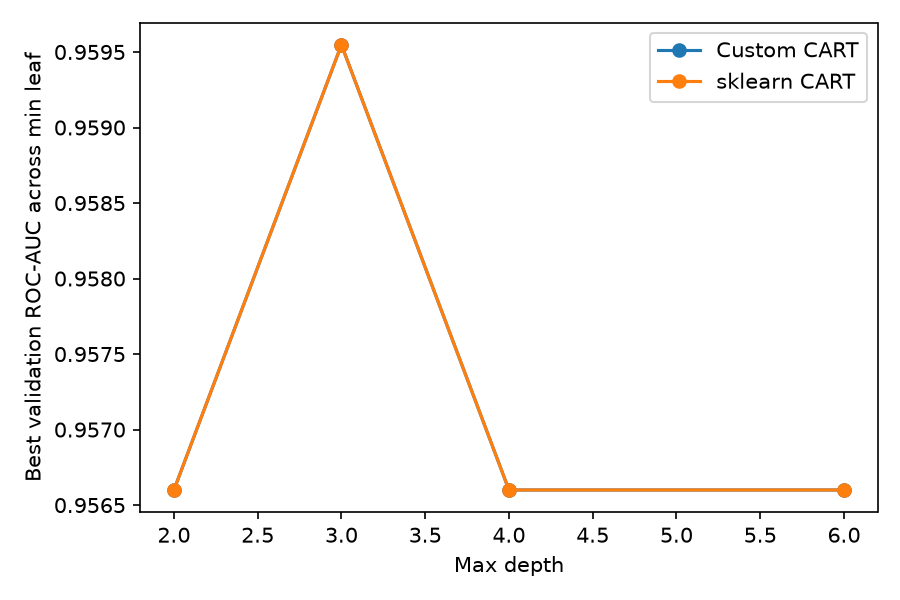

In [3]:
results=run('04')
display(results.round(4))
display(Image(filename=str(ROOT/'reports/04_trees.png')))

In [4]:
for _,r in results.iterrows():
    print(f'{r.model}: depth={int(r.depth)}, leaf={int(r.min_leaf)}, test ROC-AUC={r.roc_auc:.4f}, recall={r.recall:.4f}')

Custom CART: depth=3, leaf=8, test ROC-AUC=0.9673, recall=0.8333
sklearn CART: depth=3, leaf=8, test ROC-AUC=0.9673, recall=0.8333


## Границы реализации

Своя версия поддерживает только конечные числовые признаки и бинарные метки 0/1. Это не универсальная замена sklearn: нет встроенной работы с NaN, pruning, sample weights и категориальными признаками.